# PlasticMuonTiming: variable-SiPM signal + position reconstruction

Batch ROOT directories:

`/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies/output_edge{NEDGE}`

This notebook supports **NEDGE = 0, 1, 2, 3, 4, 5**, corresponding to **4, 8, 12, 16, 20, 24 SiPMs** respectively.

All Slurm ROOT files are loaded separately. A unique global event ID is assigned before
combining the `events` and `hits` trees, preventing duplicate Geant4 event IDs across jobs.

The notebook:
- auto-detects all SiPM IDs from the ROOT branches;
- analyzes amplitude and timing of every channel;
- infers each channel's effective spatial response from MC truth, so no SiPM geometry is hard-coded;
- compares amplitude-only, timing-only and amplitude+timing reconstruction;
- evaluates position resolution on an independent test sample.

Main reconstruction methods:
1. effective multi-channel COG;
2. amplitude quadratic regression;
3. timing quadratic regression;
4. amplitude+timing quadratic regression;
5. amplitude template $\chi^2$;
6. timing template $\chi^2$;
7. amplitude+timing template $\chi^2$.

All spatial 2D maps in this version use **regular square bins (25 mm × 25 mm)** rather than hexagonal bins.


In [1]:
# 1. Imports and configuration
from pathlib import Path
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt, uproot
from IPython.display import display

plt.rcParams.update({"figure.dpi":120,"savefig.dpi":180,"font.size":11,
                     "axes.grid":True,"grid.alpha":.25})
pd.set_option("display.max_columns",200)

# NEDGE = 0, 1, 2, 3, 4, 5 -> 4, 8, 12, 16, 20, 24 SiPMs
NEDGE=1
Length=200 # detector size [mm]
HALF=Length/2

RUN=Path(f"/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_{Length}")
INDIR=RUN/f"output_edge{NEDGE}_{Length}"
FILES=sorted(INDIR.glob("*.root"))
OUT=RUN/f"output_edge{NEDGE}_{Length}_analysis"; OUT.mkdir(parents=True,exist_ok=True)

if not FILES:
    raise FileNotFoundError(f"No ROOT files found in {INDIR}")

TRAIN_FRAC=.70
SEED=12345
NX=NY=21
MIN_TEMPLATE_EVENTS=5
RIDGE=1e-2

print(f"NEDGE : {NEDGE}  ({4+4*NEDGE} SiPMs)")
print("Input :",INDIR)
print("ROOTs :",len(FILES))
print("Output:",OUT)

NEDGE : 1  (8 SiPMs)
Input : /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_200/output_edge1_200
ROOTs : 20
Output: /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_200/output_edge1_200_analysis


In [2]:
# ============================================================
# 2D plotting helper: regular square spatial bins
# ============================================================
from scipy.stats import binned_statistic_2d

# 25 mm x 25 mm spatial bins for a 1000 x 1000 mm detector
XY_BINS = np.arange(-HALF, HALF + 10, 10)

def histmap(ax, x, y, z=None, statistic="mean",
            bins=XY_BINS, min_count=3, cbar_label=None,
            vmin=None, vmax=None):
    """
    Regular rectangular 2D spatial map.

    If z is None:
        plot event counts / bin.
    Otherwise:
        plot requested binned statistic of z.

    Bins with fewer than min_count events are masked.
    """
    x=np.asarray(x,float)
    y=np.asarray(y,float)
    good=np.isfinite(x)&np.isfinite(y)

    if z is not None:
        z=np.asarray(z,float)
        good &= np.isfinite(z)
        z=z[good]

    x=x[good]
    y=y[good]

    count,xe,ye,_=binned_statistic_2d(
        x,y,None,statistic="count",bins=[bins,bins]
    )

    if z is None:
        Z=count
    else:
        Z,xe,ye,_=binned_statistic_2d(
            x,y,z,statistic=statistic,bins=[bins,bins]
        )
        Z[count < min_count] = np.nan

    im=ax.pcolormesh(
        xe,ye,Z.T,
        shading="auto",
        vmin=vmin,vmax=vmax
    )

    ax.set_aspect("equal")

    if cbar_label is not None:
        plt.colorbar(im,ax=ax,label=cbar_label)

    return im, count

In [ ]:
# 2. Load all batch ROOTs + assign globally unique event IDs
E,H=[],[]; offset=0

for job,fname in enumerate(FILES):
    with uproot.open(fname) as f:
        e=f["events"].arrays(library="pd").reset_index(drop=True)
        h=f["hits"].arrays(library="pd").reset_index(drop=True) if "hits" in f else pd.DataFrame()

    e["event"]=e.event.astype(int)
    e["event_local"]=e.event
    e["job"]=job

    if len(h):
        h["event"]=h.event.astype(int)
        h["event_local"]=h.event
        h["job"]=job

    span=int(e.event.max())+1
    e["event"]+=offset
    if len(h): h["event"]+=offset

    E.append(e)
    if len(h): H.append(h)

    print(f"{job:2d}  {fname.name:40s}  events={len(e):6d}  offset={offset:7d}")
    offset+=span

events=pd.concat(E,ignore_index=True)
hits=pd.concat(H,ignore_index=True) if H else pd.DataFrame()

events=events.replace([np.inf,-np.inf],np.nan)
hits=hits.replace([np.inf,-np.inf],np.nan)

# sanity checks
assert events.event.is_unique, "Global event IDs are not unique."
if len(hits):
    assert hits.event.isin(events.event).all(), "Some hits cannot be matched to events."

pat=re.compile(r"^n_detected_sipm(\d+)$")
IDS=sorted(int(m.group(1)) for c in events.columns if (m:=pat.match(c)))
if not IDS and "sipm" in hits:
    IDS=sorted(hits.sipm.dropna().astype(int).unique())

NSIPM=len(IDS); EXPECTED=4+4*NEDGE

print("\nTotal events :",len(events))
print("Unique events:",events.event.nunique())
print("Event range  :",events.event.min(),events.event.max())
print("Total hits   :",len(hits))
print("SiPM IDs     :",IDS)
print("N SiPMs      :",NSIPM)

if NSIPM!=EXPECTED:
    print(f"WARNING: edge{NEDGE} is expected to contain {EXPECTED} SiPMs.")

print("\nEvent branches:\n",list(events.columns))
print("\nHit branches:\n",list(hits.columns))
display(events.head())


 0  sipm_edge1_0.root                         events= 10000  offset=      0
 1  sipm_edge1_1.root                         events= 10000  offset=  10000
 2  sipm_edge1_10.root                        events= 10000  offset=  20000
 3  sipm_edge1_11.root                        events= 10000  offset=  30000
 4  sipm_edge1_12.root                        events= 10000  offset=  40000
 5  sipm_edge1_13.root                        events= 10000  offset=  50000
 6  sipm_edge1_14.root                        events= 10000  offset=  60000
 7  sipm_edge1_15.root                        events= 10000  offset=  70000
 8  sipm_edge1_16.root                        events= 10000  offset=  80000
 9  sipm_edge1_17.root                        events= 10000  offset=  90000
10  sipm_edge1_18.root                        events= 10000  offset= 100000
11  sipm_edge1_19.root                        events= 10000  offset= 110000
12  sipm_edge1_2.root                         events= 10000  offset= 120000
13  sipm_edg

In [ ]:
# Check local/global event mapping
display(events[["job","event_local","event"]].groupby("job").agg(["min","max","count"]))

print("\nDuplicate global event IDs :",events.event.duplicated().sum())
print("Duplicate local event IDs  :",events.event_local.duplicated().sum())

event_local                event               
            min   max  count     min     max  count
job                                                
0             0  9999  10000       0    9999  10000
1             0  9999  10000   10000   19999  10000
2             0  9999  10000   20000   29999  10000
3             0  9999  10000   30000   39999  10000
4             0  9999  10000   40000   49999  10000
5             0  9999  10000   50000   59999  10000
6             0  9999  10000   60000   69999  10000
7             0  9999  10000   70000   79999  10000
8             0  9999  10000   80000   89999  10000
9             0  9999  10000   90000   99999  10000
10            0  9999  10000  100000  109999  10000
11            0  9999  10000  110000  119999  10000
12            0  9999  10000  120000  129999  10000
13            0  9999  10000  130000  139999  10000
14            0  9999  10000  140000  149999  10000
15            0  9999  10000  150000  159999  10000
16            0  9999  10000  160000  169999  10000
17            0  9999  10000  170000  179999  10000
18            0  9999  10000  180000  189999  10000
19            0  9999  10000  190000  199999  10000


Duplicate global event IDs : 0
Duplicate local event IDs  : 190000


In [ ]:
# 3. Standardize truth, amplitude and timing variables
if "event" not in events: events["event"]=np.arange(len(events))
events["event"]=events.event.astype(int)
if len(hits):
    hits["event"]=hits.event.astype(int)
    hits["sipm"]=hits.sipm.astype(int)

def first(df,names): return next((x for x in names if x in df),None)

X=first(events,["source_x_mm","x_source_mm","source_x","x_true_mm"])
Y=first(events,["source_y_mm","y_source_mm","source_y","y_true_mm"])
if X is None or Y is None: raise KeyError("Truth X/Y branches not found.")
events["source_x_mm"]=events[X]; events["source_y_mm"]=events[Y]

# detected counts, reconstructed from hits if event branches are absent
for i in IDS:
    c=f"n_detected_sipm{i}"
    if c not in events and len(hits):
        s=hits[hits.sipm==i].groupby("event").size()
        events[c]=events.event.map(s).fillna(0)

Ncols=[f"n_detected_sipm{i}" for i in IDS]
events["Ntot"]=events[Ncols].sum(axis=1)
for i in IDS: events[f"f{i}"]=events[f"n_detected_sipm{i}"]/events.Ntot.replace(0,np.nan)

# photon timing
THIT=first(hits,["t_ns","t_plot_ns","time_ns","arrival_time_ns","global_time_ns"]) if len(hits) else None
if THIT:
    hs=hits.dropna(subset=[THIT]).sort_values(["event","sipm",THIT])
    timing={
        "t_first":hs.groupby(["event","sipm"])[THIT].first(),
        "t_first3":hs.groupby(["event","sipm"]).head(3).groupby(["event","sipm"])[THIT].mean(),
        "t_first5":hs.groupby(["event","sipm"]).head(5).groupby(["event","sipm"])[THIT].mean(),
    }
    for name,s in timing.items():
        w=s.unstack(); w.columns=[f"{name}{int(i)}" for i in w.columns]
        events=events.merge(w.reset_index(),on="event",how="left")
else:
    for i in IDS:
        c=first(events,[f"first_time_sipm{i}_ns",f"first_time_sipm{i}",f"t_first_sipm{i}_ns"])
        if c: events[f"t_first3{i}"]=events[c]

T=[f"t_first3{i}" for i in IDS if f"t_first3{i}" in events]
if not T: raise KeyError("No SiPM timing information found.")
events["t_ref"]=events[T].median(axis=1,skipna=True)
for i in IDS:
    events[f"dt{i}"]=events.get(f"t_first3{i}",np.nan)-events.t_ref
events["logN"]=np.log1p(events.Ntot)

print("Photon time branch:",THIT)
print("Mean total detected photons/event:",events.Ntot.mean())
print("Zero signal fraction:",f"{(events.Ntot==0).mean():.3%}")

Photon time branch: t_ns
Mean total detected photons/event: 803.444795
Zero signal fraction: 0.000%


In [ ]:
# 4. Per-SiPM signal summary
rows=[]
for i in IDS:
    n=events[f"n_detected_sipm{i}"].to_numpy(float)
    t=events[f"t_first3{i}"].to_numpy(float) if f"t_first3{i}" in events else np.full(len(events),np.nan)
    r={"SiPM":i,"mean_N":np.nanmean(n),"std_N":np.nanstd(n),
       "P(N>=1)":np.mean(n>=1),"mean_fraction":np.nanmean(events[f"f{i}"]),
       "mean_first3_ns":np.nanmean(t),"std_first3_ns":np.nanstd(t)}
    for c,k in [(f"n_reach_sipm{i}","mean_reached"),
                (f"n_scint_detected_sipm{i}","mean_scint"),
                (f"n_cherenkov_detected_sipm{i}","mean_cherenkov")]:
        if c in events:r[k]=events[c].mean()
    if f"n_reach_sipm{i}" in events:
        den=events[f"n_reach_sipm{i}"].sum()
        r["det/reach"]=events[f"n_detected_sipm{i}"].sum()/den if den else np.nan
    rows.append(r)

sipm_summary=pd.DataFrame(rows).set_index("SiPM")
display(sipm_summary.round(4))
sipm_summary.to_csv(OUT/"sipm_signal_summary.csv")

,mean_N,std_N,P(N>=1),mean_fraction,mean_first3_ns,std_first3_ns,mean_reached,mean_scint,mean_cherenkov,det/reach
SiPM,,,,,,,,,,
0,200.8851,82.8177,1.0,0.2500,0.8913,0.3437,427.6694,197.6832,3.2019,0.4697
1,200.7430,81.6405,1.0,0.2499,0.8904,0.3434,427.3562,197.5388,3.2042,0.4697
2,201.0209,83.1098,1.0,0.2501,0.8904,0.3440,428.0107,197.8108,3.2101,0.4697
3,200.7958,81.5268,1.0,0.2500,0.8909,0.3439,427.4357,197.5906,3.2053,0.4698


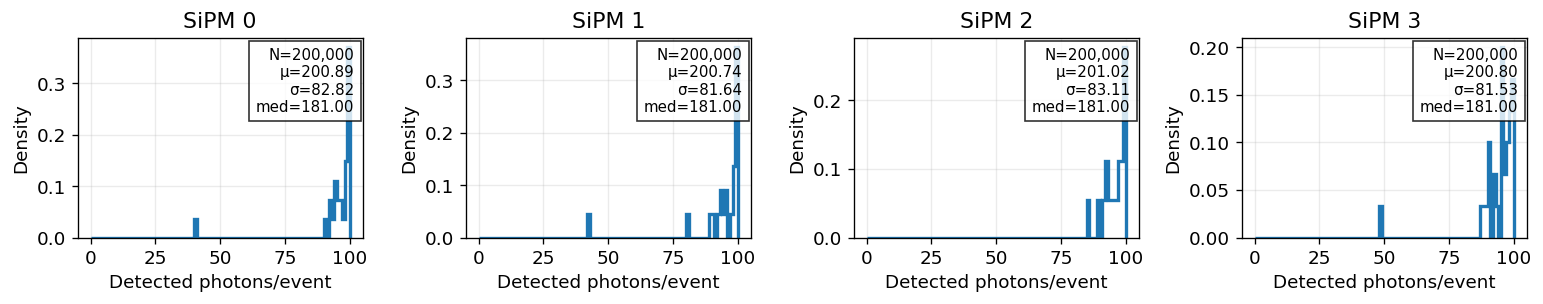

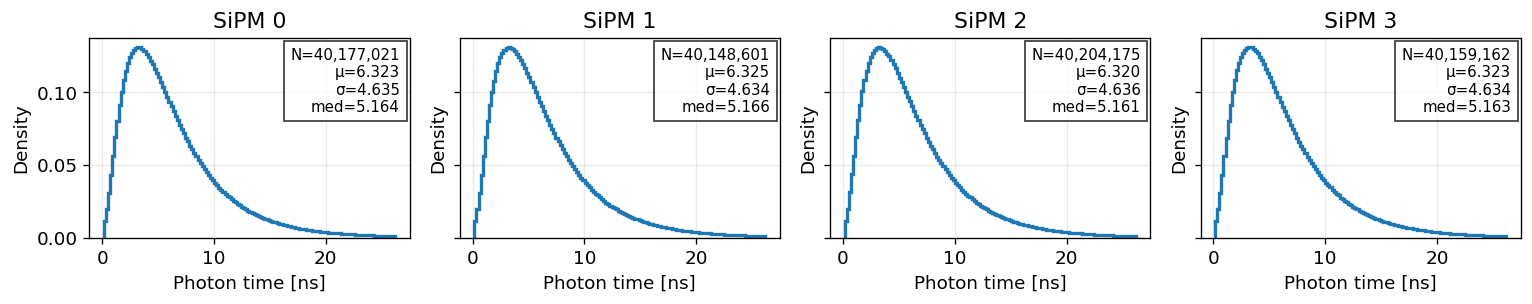

In [ ]:
# 5. Detected-signal and dN/dt distributions
NROW=int(np.ceil(NSIPM/4))

# Signal
fig,ax=plt.subplots(NROW,4,figsize=(13,8*NROW/3),squeeze=False)
for a,i in zip(ax.flat,IDS):
    x=events[f"n_detected_sipm{i}"].dropna().to_numpy(float)
    a.hist(x,100,(0,100),histtype="step",density=True,linewidth=2)
    a.text(.97,.95,f"N={len(x):,}\nμ={x.mean():.2f}\nσ={x.std():.2f}\nmed={np.median(x):.2f}",
           transform=a.transAxes,ha="right",va="top",fontsize=9,
           bbox=dict(fc="white",alpha=.8))
    a.set(title=f"SiPM {i}",xlabel="Detected photons/event",ylabel="Density")
for a in ax.flat[NSIPM:]: a.axis("off")
plt.tight_layout(); plt.savefig(OUT/f"01_signal_{NSIPM}sipm.png",bbox_inches="tight"); plt.show()


# dN/dt
if THIT:
    q=hits[THIT].dropna(); lo,hi=np.quantile(q,[.001,.995])
    fig,ax=plt.subplots(NROW,4,figsize=(13,8*NROW/3),squeeze=False,sharex=True,sharey=True)
    for a,i in zip(ax.flat,IDS):
        t=hits.loc[hits.sipm==i,THIT].dropna().to_numpy(float)
        a.hist(t,140,(lo,hi),histtype="step",density=True,linewidth=2)
        a.text(.97,.95,f"N={len(t):,}\nμ={t.mean():.3f}\nσ={t.std():.3f}\nmed={np.median(t):.3f}",
               transform=a.transAxes,ha="right",va="top",fontsize=9,
               bbox=dict(fc="white",alpha=.8))
        a.set(title=f"SiPM {i}",xlabel="Photon time [ns]",ylabel="Density")
    for a in ax.flat[NSIPM:]: a.axis("off")
    plt.tight_layout(); plt.savefig(OUT/f"02_dNdt_{NSIPM}sipm.png",bbox_inches="tight"); plt.show()


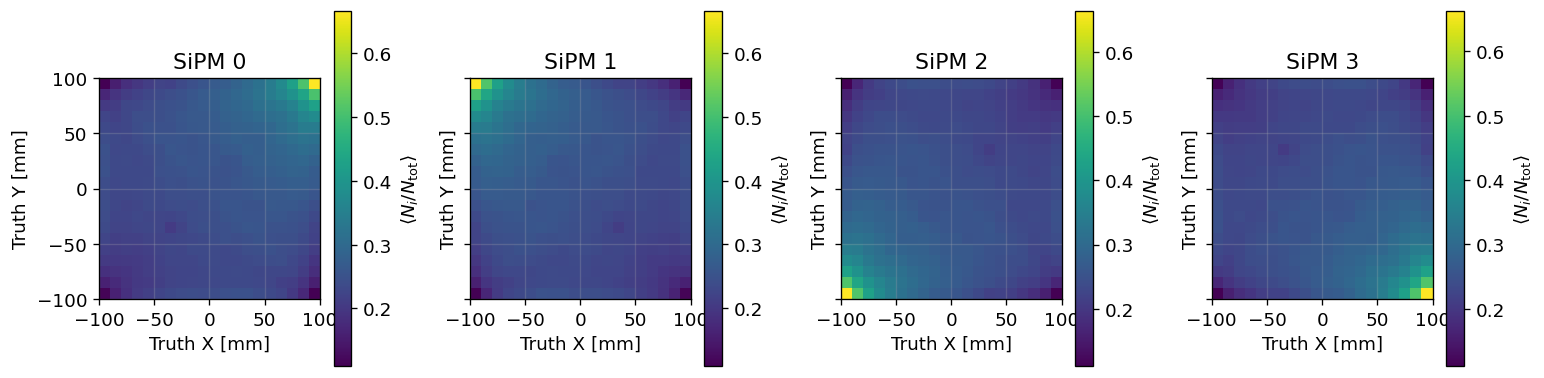

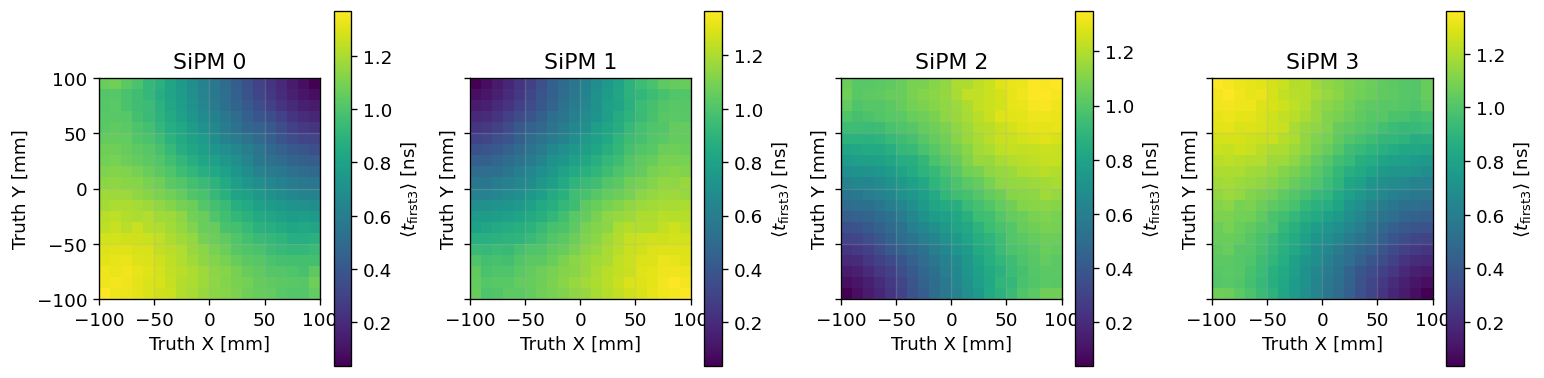

In [ ]:
# 6. 2D response maps for all SiPMs
def maps(prefix,label,name):
    NROW=int(np.ceil(NSIPM/4))
    fig,ax=plt.subplots(NROW,4,figsize=(13,10*NROW/3),squeeze=False,sharex=True,sharey=True)
    for a,i in zip(ax.flat,IDS):
        c=f"{prefix}{i}"
        if c not in events:
            a.axis("off")
            continue

        z=events[c].to_numpy(float)

        histmap(a,events["source_x_mm"],events["source_y_mm"],z=z,statistic="mean",bins=XY_BINS,min_count=3,cbar_label=label)
        a.set(title=f"SiPM {i}",xlabel="Truth X [mm]",ylabel="Truth Y [mm]",xlim=(-HALF,HALF),ylim=(-HALF,HALF))

    for a in ax.flat[NSIPM:]: a.axis("off")
    plt.tight_layout()
    plt.savefig(OUT/name,bbox_inches="tight")
    plt.show()

maps("f",r"$\langle N_i/N_{\rm tot}\rangle$","03_fraction_maps.png")
maps("t_first3",r"$\langle t_{\rm first3}\rangle$ [ns]","04_timing_maps.png")


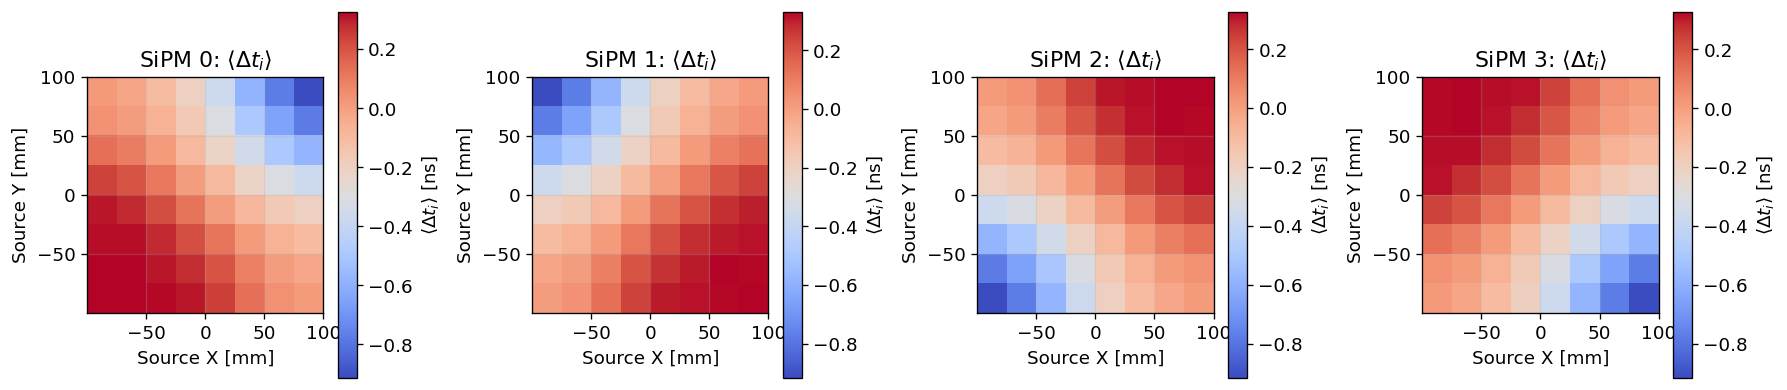

In [ ]:
# Figure 4b: <Δt_i>(x,y)
fig,axs=plt.subplots(int(np.ceil(NSIPM/4)),4,figsize=(15,3.5*np.ceil(NSIPM/4)))
axs=np.ravel(axs)

xb=np.arange(events.source_x_mm.min(),events.source_x_mm.max()+25,25)
yb=np.arange(events.source_y_mm.min(),events.source_y_mm.max()+25,25)

for ax,i in zip(axs,IDS):
    x,y,z=events.source_x_mm.values,events.source_y_mm.values,events[f"dt{i}"].values
    ix,iy=np.digitize(x,xb)-1,np.digitize(y,yb)-1
    M=np.array([[np.nanmean(z[(ix==xx)&(iy==yy)]) for xx in range(len(xb)-1)]
                for yy in range(len(yb)-1)])

    im=ax.imshow(M,origin="lower",extent=[*xb[[0,-1]],*yb[[0,-1]]],
                 aspect="equal",cmap="coolwarm")
    ax.set(title=fr"SiPM {i}: $\langle\Delta t_i\rangle$",
           xlabel="Source X [mm]",ylabel="Source Y [mm]")
    plt.colorbar(im,ax=ax,label=r"$\langle\Delta t_i\rangle$ [ns]")

for ax in axs[len(IDS):]: ax.axis("off")

plt.tight_layout()
plt.savefig(OUT/f"04b_dt_maps_{NSIPM}sipm.png",dpi=200,bbox_inches="tight")
plt.show()

## 7. Identify the channel positions from their response

Instead of guessing which channel number is a corner or edge sensor, the notebook calculates an effective response centroid

$$
(x_i^\mathrm{eff},y_i^\mathrm{eff})
=
\frac{\sum_e f_{ie}(x_e,y_e)}{\sum_e f_{ie}}.
$$

The resulting figure should reveal the channel-number topology: four corner-like channels plus the available edge channels.


,x_eff_mm,y_eff_mm
SiPM,,
0,5.54,5.60
1,-5.68,5.60
2,-5.73,-5.70
3,5.57,-5.65


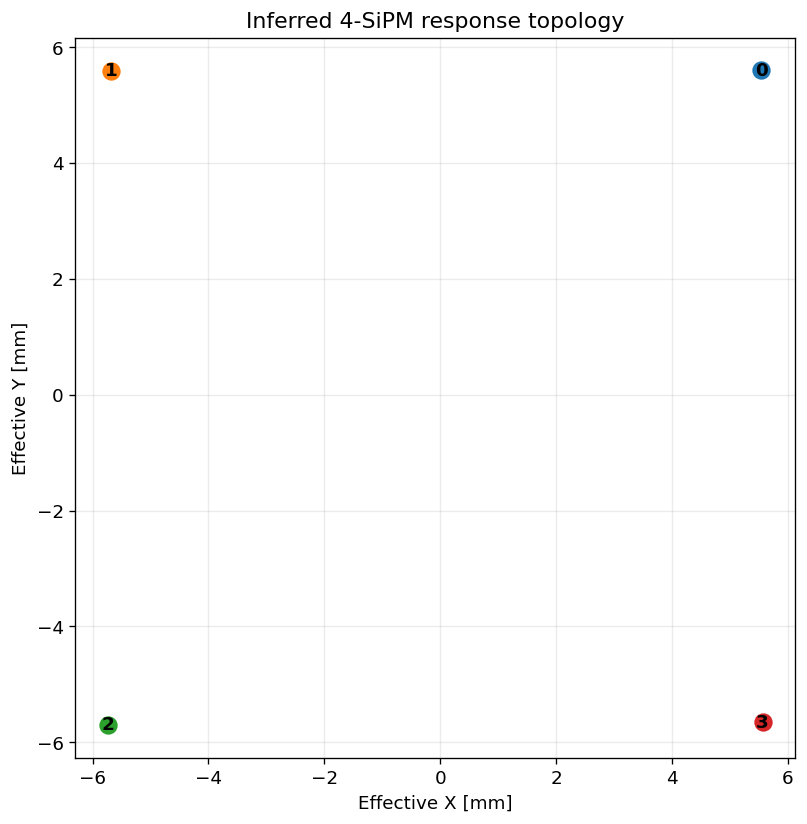

In [ ]:
# 7. Inferred response topology
eff={}
for i in IDS:
    w=events[f"f{i}"].fillna(0).to_numpy(float)
    s=w.sum()
    eff[i]=(np.sum(w*events.source_x_mm)/s,np.sum(w*events.source_y_mm)/s) if s else (np.nan,np.nan)

eff_df=pd.DataFrame([{"SiPM":i,"x_eff_mm":eff[i][0],"y_eff_mm":eff[i][1]} for i in IDS]).set_index("SiPM")
display(eff_df.round(2)); eff_df.to_csv(OUT/"sipm_effective_positions.csv")

fig,ax=plt.subplots(figsize=(7,7))
for i,(x,y) in eff.items():
    ax.scatter(x,y,s=100); ax.text(x,y,str(i),ha="center",va="center",fontweight="bold")
ax.set(xlabel="Effective X [mm]",ylabel="Effective Y [mm]",
       title=f"Inferred {NSIPM}-SiPM response topology",aspect="equal")
plt.tight_layout(); plt.savefig(OUT/"05_inferred_topology.png",bbox_inches="tight"); plt.show()

In [ ]:
# 8. Train/test split
base=events[np.isfinite(events.source_x_mm)&np.isfinite(events.source_y_mm)&(events.Ntot>0)].copy().reset_index(drop=True)
rng=np.random.default_rng(SEED); idx=rng.permutation(len(base)); n=int(TRAIN_FRAC*len(base))
train=base.iloc[idx[:n]].reset_index(drop=True)
test =base.iloc[idx[n:]].reset_index(drop=True)
print(f"Usable={len(base):,}, train={len(train):,}, test={len(test):,}")

Usable=200,000, train=140,000, test=60,000


In [ ]:
# 9. Reconstruction functions
def qexpand(X):
    X=np.asarray(X,float); out=[np.ones((len(X),1)),X,X**2]
    out += [X[:,i:i+1]*X[:,j:j+1] for i in range(X.shape[1]) for j in range(i+1,X.shape[1])]
    return np.hstack(out)

def ridge_xy(tr,te,feat,lam=1e-2):
    med=tr[feat].median()
    A=tr[feat].fillna(med).to_numpy(float); B=te[feat].fillna(med).to_numpy(float)
    mu=A.mean(0); sd=A.std(0); sd[~np.isfinite(sd)|(sd==0)]=1
    A=qexpand((A-mu)/sd); B=qexpand((B-mu)/sd)
    Y=tr[["source_x_mm","source_y_mm"]].to_numpy(float)
    G=A.T@A+lam*np.eye(A.shape[1]); G[0,0]-=lam
    return B@np.linalg.solve(G,A.T@Y)

def template_xy(tr,te,feat,nx=21,ny=21,minn=5,chunk=1500):
    med=tr[feat].median()
    A=tr[feat].fillna(med); Q=te[feat].fillna(med).to_numpy(float)
    scale=A.std().to_numpy(float); scale[~np.isfinite(scale)|(scale<1e-9)]=1
    xe=np.linspace(tr.source_x_mm.min(),tr.source_x_mm.max(),nx+1)
    ye=np.linspace(tr.source_y_mm.min(),tr.source_y_mm.max(),ny+1)
    d=tr[["source_x_mm","source_y_mm"]].copy(); d[feat]=A
    d["ix"]=np.clip(np.digitize(d.source_x_mm,xe)-1,0,nx-1)
    d["iy"]=np.clip(np.digitize(d.source_y_mm,ye)-1,0,ny-1)
    g=d.groupby(["ix","iy"]); good=g.size(); good=good[good>=minn].index
    R=[]
    for k in good:
        z=g.get_group(k)
        R.append([z.source_x_mm.mean(),z.source_y_mm.mean(),*z[feat].mean().to_numpy(float)])
    R=np.asarray(R,float); pos=R[:,:2]; resp=R[:,2:]/scale; Q=Q/scale
    out=np.empty((len(te),2))
    for s in range(0,len(te),chunk):
        q=Q[s:s+chunk]; chi=((q[:,None,:]-resp[None,:,:])**2).sum(2)
        out[s:s+len(q)]=pos[np.argmin(chi,1)]
    return out,len(pos)

def metrics(name,truth,xy):
    xt=truth.source_x_mm.to_numpy(float); yt=truth.source_y_mm.to_numpy(float)
    xr,yr=xy[:,0],xy[:,1]; m=np.isfinite(xr)&np.isfinite(yr)
    dx=xr[m]-xt[m]; dy=yr[m]-yt[m]; r=np.hypot(dx,dy)
    sx,sy=np.std(dx,ddof=1),np.std(dy,ddof=1)
    return {"method":name,"N":m.sum(),"bias_x_mm":dx.mean(),"bias_y_mm":dy.mean(),
            "sigma_x_mm":sx,"sigma_y_mm":sy,"sigma_xy_mm":np.sqrt((sx*sx+sy*sy)/2),
            "FWHM_x_mm":2.355*sx,"FWHM_y_mm":2.355*sy,
            "RMSE_x_mm":np.sqrt(np.mean(dx*dx)),"RMSE_y_mm":np.sqrt(np.mean(dy*dy)),
            "R68_mm":np.quantile(r,.68),"R90_mm":np.quantile(r,.90)}

In [ ]:
# 10. Run all reconstruction algorithms
F=[f"f{i}" for i in IDS]
D=[f"dt{i}" for i in IDS]
pred={}

# effective COG baseline
N=test[[f"n_detected_sipm{i}" for i in IDS]].to_numpy(float)
P=np.array([eff[i] for i in IDS])
pred[f"{NSIPM}-SiPM effective COG"]=(N@P)/N.sum(1,keepdims=True)

# regressions
pred["Amplitude regression"]=ridge_xy(train,test,F+["logN"],RIDGE)
pred["Timing regression"]=ridge_xy(train,test,D,RIDGE)
pred["Amplitude + timing regression"]=ridge_xy(train,test,F+D+["logN"],RIDGE)

# response templates
pred["Amplitude template chi2"],na=template_xy(train,test,F,NX,NY,MIN_TEMPLATE_EVENTS)
pred["Timing template chi2"],nt=template_xy(train,test,D,NX,NY,MIN_TEMPLATE_EVENTS)
pred["Amplitude + timing template chi2"],nat=template_xy(train,test,F+D,NX,NY,MIN_TEMPLATE_EVENTS)

print("Templates:",{"A":na,"T":nt,"A+T":nat})

/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_3397/1769165931.py:9: RuntimeWarning: divide by zero encountered in matmul
  pred[f"{NSIPM}-SiPM effective COG"]=(N@P)/N.sum(1,keepdims=True)
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_3397/1769165931.py:9: RuntimeWarning: overflow encountered in matmul
  pred[f"{NSIPM}-SiPM effective COG"]=(N@P)/N.sum(1,keepdims=True)
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_3397/1769165931.py:9: RuntimeWarning: invalid value encountered in matmul
  pred[f"{NSIPM}-SiPM effective COG"]=(N@P)/N.sum(1,keepdims=True)
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_3397/677820924.py:14: RuntimeWarning: divide by zero encountered in matmul
  return B@np.linalg.solve(G,A.T@Y)
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_3397/677820924.py:14: RuntimeWarning: overflow encountered in matmul
  return B@np.linalg.solve(G,A.T@Y)
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_3397/677820

Templates: {'A': 441, 'T': 441, 'A+T': 441}


N events = 60000
sigma_x  = 48.83 mm
sigma_y  = 48.61 mm
sigma_xy = 68.90 mm
R68      = 79.49 mm
R90      = 91.12 mm


/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_3397/3646162762.py:39: RuntimeWarning: divide by zero encountered in matmul
  xy[ok] = (N[ok] @ POS) / S[ok,None]
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_3397/3646162762.py:39: RuntimeWarning: overflow encountered in matmul
  xy[ok] = (N[ok] @ POS) / S[ok,None]
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_3397/3646162762.py:39: RuntimeWarning: invalid value encountered in matmul
  xy[ok] = (N[ok] @ POS) / S[ok,None]


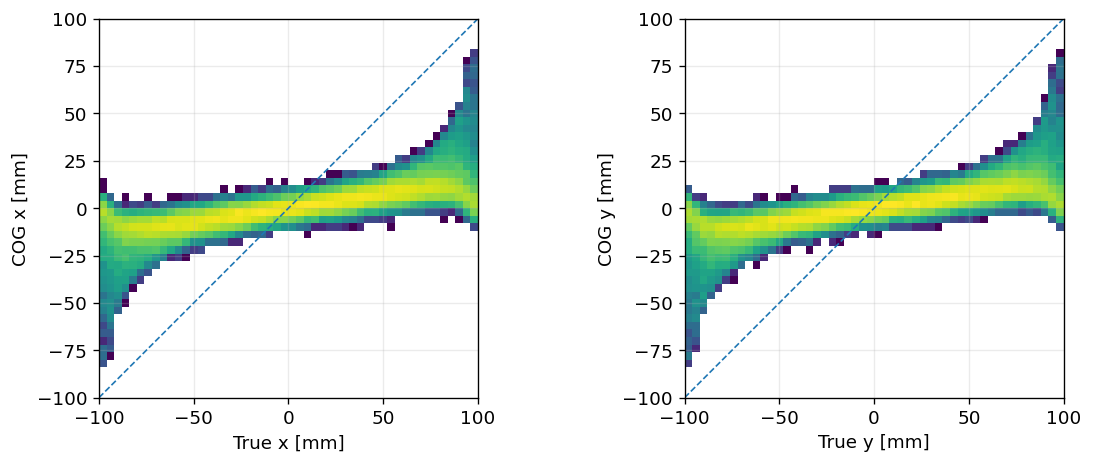

In [ ]:
# ============================================================
# Conventional COG using REAL SiPM geometry positions
# ============================================================
from matplotlib.colors import LogNorm
# ---- REAL SiPM positions [mm] ----
# Replace these by the exact coordinates from DetectorConstruction
# Example here: 4 corner SiPMs on a 1000 x 1000 mm plate
# POS = np.array([
#     [ 497.8539309,  497.8539309],   # SiPM 0: +X,+Y
#     [-497.8539309,  497.8539309],   # SiPM 1: -X,+Y
#     [-497.8539309, -497.8539309],   # SiPM 2: -X,-Y
#     [ 497.8539309, -497.8539309],   # SiPM 3: +X,-Y
# ])

def get_POS(NEDGE):
    EDGE = HALF - 2.1460690809
    pos = [[ EDGE, EDGE],[-EDGE, EDGE],[-EDGE,-EDGE],[ EDGE,-EDGE]]

    if NEDGE:
        u = np.linspace(-EDGE, EDGE, NEDGE+2)[1:-1]
        pos += [[ x, EDGE] for x in u]       # +Y: left -> right
        pos += [[EDGE,-y] for y in u]        # +X: top -> bottom
        pos += [[-x,-EDGE] for x in u]       # -Y: right -> left
        pos += [[-EDGE,y] for y in u]        # -X: bottom -> top

    return np.asarray(pos,float)

POS=get_POS(NEDGE)
ids = np.arange(len(POS))

# detected photons for each SiPM
N = test[[f"n_detected_sipm{i}" for i in ids]].to_numpy(float)

# conventional COG
S = N.sum(1)
ok = S > 0

xy = np.full((len(test),2), np.nan)
xy[ok] = (N[ok] @ POS) / S[ok,None]

# truth
truth = test[["source_x_mm","source_y_mm"]].to_numpy()
good = ok & np.isfinite(xy).all(1)

dx = xy[good,0] - truth[good,0]
dy = xy[good,1] - truth[good,1]
dr = np.hypot(dx,dy)

sx,sy = np.std(dx),np.std(dy)
sxy = np.sqrt(sx**2 + sy**2)
r68,r90 = np.percentile(dr,[68,90])

print(f"N events = {good.sum()}")
print(f"sigma_x  = {sx:.2f} mm")
print(f"sigma_y  = {sy:.2f} mm")
print(f"sigma_xy = {sxy:.2f} mm")
print(f"R68      = {r68:.2f} mm")
print(f"R90      = {r90:.2f} mm")

# ---- truth vs reconstructed position ----
fig,ax = plt.subplots(1,2,figsize=(10,4))

for a,j,l in zip(ax,[0,1],["x","y"]):
    a.hist2d(
        truth[good,j], xy[good,j],
        bins=50,
        range=[[-HALF,HALF],[-HALF,HALF]],
        norm=LogNorm()
    )
    a.plot([-HALF,HALF],[-HALF,HALF],"--",lw=1)
    a.set(
        xlabel=f"True {l} [mm]",
        ylabel=f"COG {l} [mm]",
        xlim=(-HALF,HALF),
        ylim=(-HALF,HALF),
        aspect="equal"
    )

plt.tight_layout()
plt.show()

# make available for later comparison
pred["Conventional COG"] = xy

## Photon Thinning Test (Statistics Impacts)

/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_3397/735133246.py:19: RuntimeWarning: divide by zero encountered in matmul
  xy[ok] = N[ok] @ POS / S[ok,None]
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_3397/735133246.py:19: RuntimeWarning: overflow encountered in matmul
  xy[ok] = N[ok] @ POS / S[ok,None]
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_3397/735133246.py:19: RuntimeWarning: invalid value encountered in matmul
  xy[ok] = N[ok] @ POS / S[ok,None]


NEDGE=0, NSIPM=4
 f    <Nγ>    sigma_x   sigma_y   sigma_xy    R68 [mm]
1.00  804.17     31.23     31.03      44.03     44.15
0.75  603.14     32.53     32.33      45.86     46.55
0.50  402.20     34.78     34.63      49.08     50.03
0.25  201.06     39.51     39.27      55.71     58.83
0.10   80.44     46.25     46.01      65.24     70.68


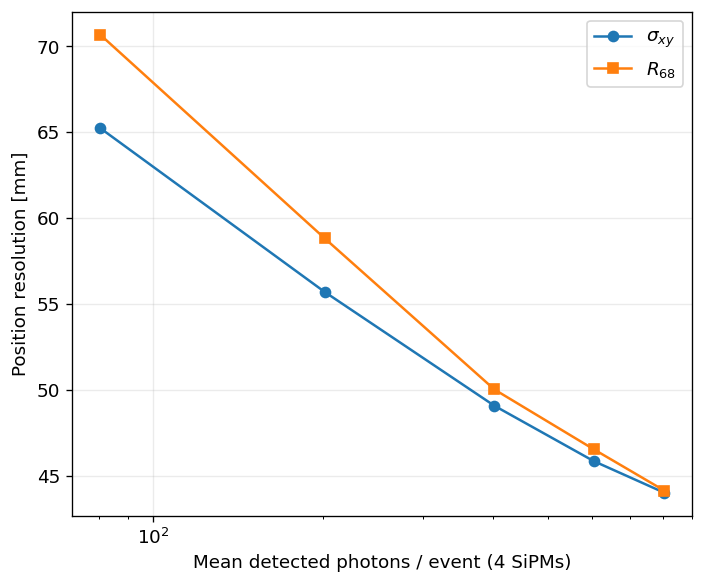

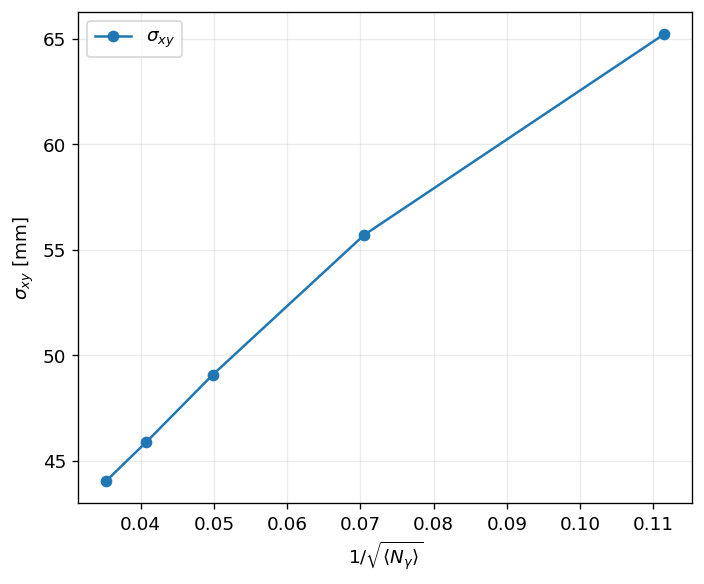

In [ ]:
# ============================================================
# Photon-statistics test: random photon thinning
# ============================================================
NSIPM = len(POS)

truth = test[["source_x_mm","source_y_mm"]].to_numpy(float)
N0 = test[[f"n_detected_sipm{i}" for i in range(NSIPM)]].to_numpy(int)

rng = np.random.default_rng(42)
fractions = [1,.75,.5,.25,.1]
R = []

for f in fractions:
    N = N0 if f==1 else rng.binomial(N0,f)
    S = N.sum(1)
    ok = S > 0

    xy = np.full((len(N),2),np.nan)
    xy[ok] = N[ok] @ POS / S[ok,None]

    # remove mean COG response compression
    cal = np.full_like(xy,np.nan)
    for j in range(2):
        p = np.polyfit(xy[ok,j],truth[ok,j],3)
        cal[ok,j] = np.polyval(p,xy[ok,j])

    dx = cal[ok,0] - truth[ok,0]
    dy = cal[ok,1] - truth[ok,1]
    dr = np.hypot(dx,dy)

    sx,sy = np.std(dx),np.std(dy)
    sxy = np.hypot(sx,sy)
    r68 = np.percentile(dr,68)

    R.append([f,N[ok].sum(1).mean(),sx,sy,sxy,r68])

R = np.array(R)

print(f"NEDGE={NEDGE}, NSIPM={NSIPM}")
print(" f    <Nγ>    sigma_x   sigma_y   sigma_xy    R68 [mm]")
for r in R:
    print(f"{r[0]:.2f}  {r[1]:6.2f}   {r[2]:7.2f}   {r[3]:7.2f}   {r[4]:8.2f}   {r[5]:7.2f}")

fig,ax = plt.subplots(figsize=(6,5))
ax.plot(R[:,1],R[:,4],"o-",label=r"$\sigma_{xy}$")
ax.plot(R[:,1],R[:,5],"s-",label=r"$R_{68}$")
ax.set(
    xlabel=f"Mean detected photons / event ({NSIPM} SiPMs)",
    ylabel="Position resolution [mm]",
    xscale="log"
)
ax.grid(alpha=.25)
ax.legend()
plt.tight_layout(); plt.savefig(OUT/f"06a_photon_stats_{NSIPM}sipm.png",bbox_inches="tight")
plt.show()

fig,ax = plt.subplots(figsize=(6,5))
x = 1/np.sqrt(R[:,1])
ax.plot(x,R[:,4],"o-",label=r"$\sigma_{xy}$")
ax.set(
    xlabel=r"$1/\sqrt{\langle N_\gamma\rangle}$",
    ylabel=r"$\sigma_{xy}$ [mm]"
)
ax.grid(alpha=.25)
ax.legend()
plt.tight_layout(); plt.savefig(OUT/f"06b_photon_uncertainty_{NSIPM}sipm.png",bbox_inches="tight")
plt.show()

In [ ]:
# 11. Position-resolution table
summary=pd.DataFrame([metrics(k,test,v) for k,v in pred.items()]).sort_values("R68_mm").reset_index(drop=True)
display(summary.round(3))
summary.to_csv(OUT/"position_resolution_summary.csv",index=False)
best=summary.iloc[0].method
print("Best by R68:",best)

,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,FWHM_x_mm,FWHM_y_mm,RMSE_x_mm,RMSE_y_mm,R68_mm,R90_mm
0,Amplitude + timing template chi2,60000,-0.166,-0.046,19.775,19.837,19.806,46.571,46.717,19.776,19.837,26.565,45.661
1,Amplitude + timing regression,60000,-0.034,-0.138,18.552,18.473,18.513,43.691,43.504,18.552,18.473,27.393,40.430
2,Timing regression,60000,-0.048,-0.167,19.247,19.170,19.209,45.328,45.146,19.247,19.171,28.722,41.641
3,Timing template chi2,60000,0.144,0.004,21.041,21.006,21.023,49.551,49.469,21.041,21.006,30.618,46.389
4,Amplitude regression,60000,-0.028,-0.280,31.419,31.237,31.328,73.991,73.562,31.419,31.238,43.968,67.815
5,Amplitude template chi2,60000,-0.104,0.175,35.550,35.208,35.379,83.721,82.914,35.550,35.208,47.291,84.498
6,Conventional COG,60000,-0.050,-0.207,48.832,48.613,48.723,114.999,114.484,48.831,48.613,79.491,91.122
7,4-SiPM effective COG,60000,-0.145,-0.249,57.298,57.112,57.205,134.938,134.499,57.298,57.112,92.416,110.324


Best by R68: Amplitude + timing template chi2


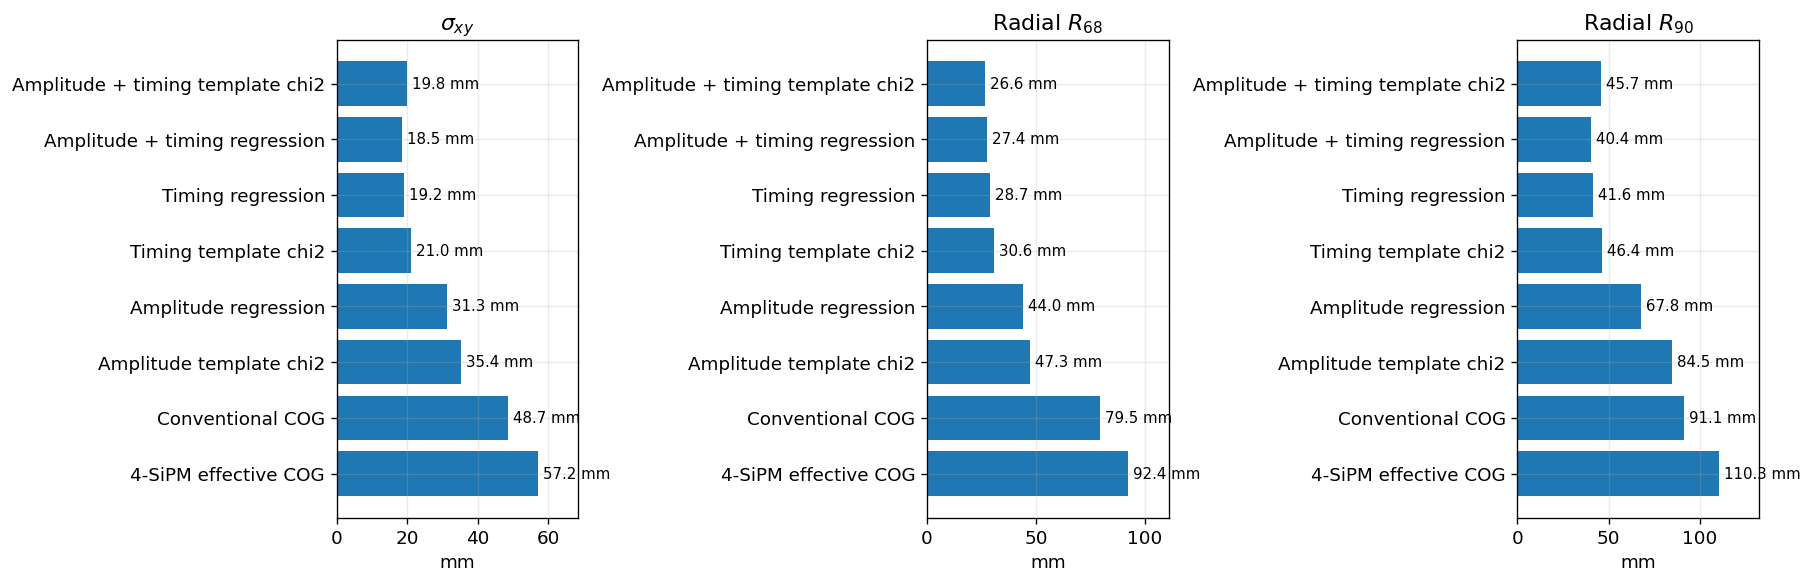

Best σxy : Amplitude + timing regression
Best R68 : Amplitude + timing template chi2
Best R90 : Amplitude + timing regression


In [ ]:
# 12. Compare algorithms
fig,ax=plt.subplots(1,3,figsize=(15,5))
for a,c,title in zip(ax,["sigma_xy_mm","R68_mm","R90_mm"],
                     [r"$\sigma_{xy}$","Radial $R_{68}$","Radial $R_{90}$"]):
    values = summary[c].to_numpy()
    bars = a.barh(summary.method, values)
    a.bar_label(bars, labels=[f"{value:.1f} mm" for value in values],
                padding=3, fontsize=9)
    a.invert_yaxis()
    xmax = np.nanmax(values)
    a.set_xlim(0, 1.20*xmax if xmax > 0 else 1)
    a.set(xlabel="mm", title=title)
plt.tight_layout(); plt.savefig(OUT/"06_algorithm_comparison.png",bbox_inches="tight"); plt.show()
best_sigma = summary.loc[summary["sigma_xy_mm"].idxmin(),"method"]
best_R68   = summary.loc[summary["R68_mm"].idxmin(),"method"]
best_R90   = summary.loc[summary["R90_mm"].idxmin(),"method"]

print("Best σxy :",best_sigma)
print("Best R68 :",best_R68)
print("Best R90 :",best_R90)

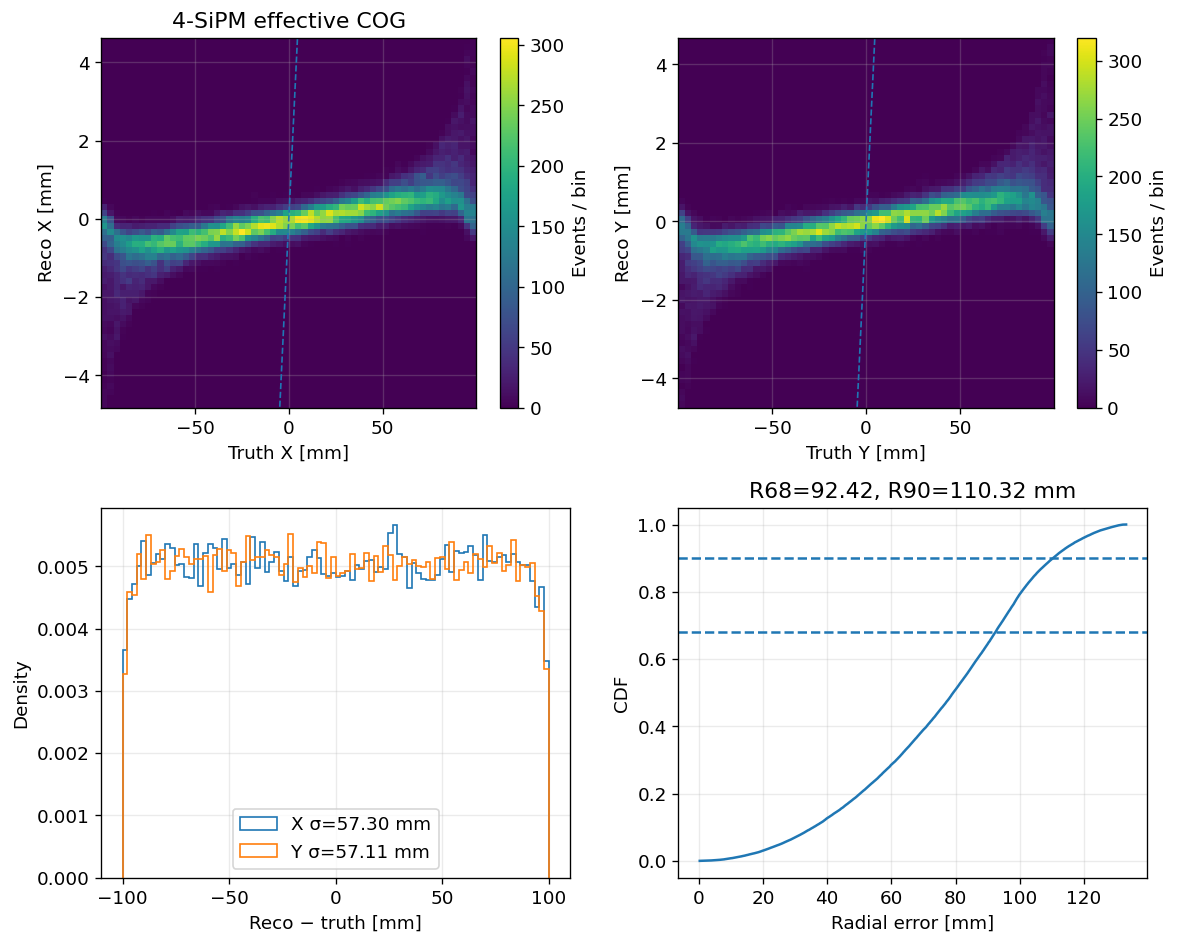

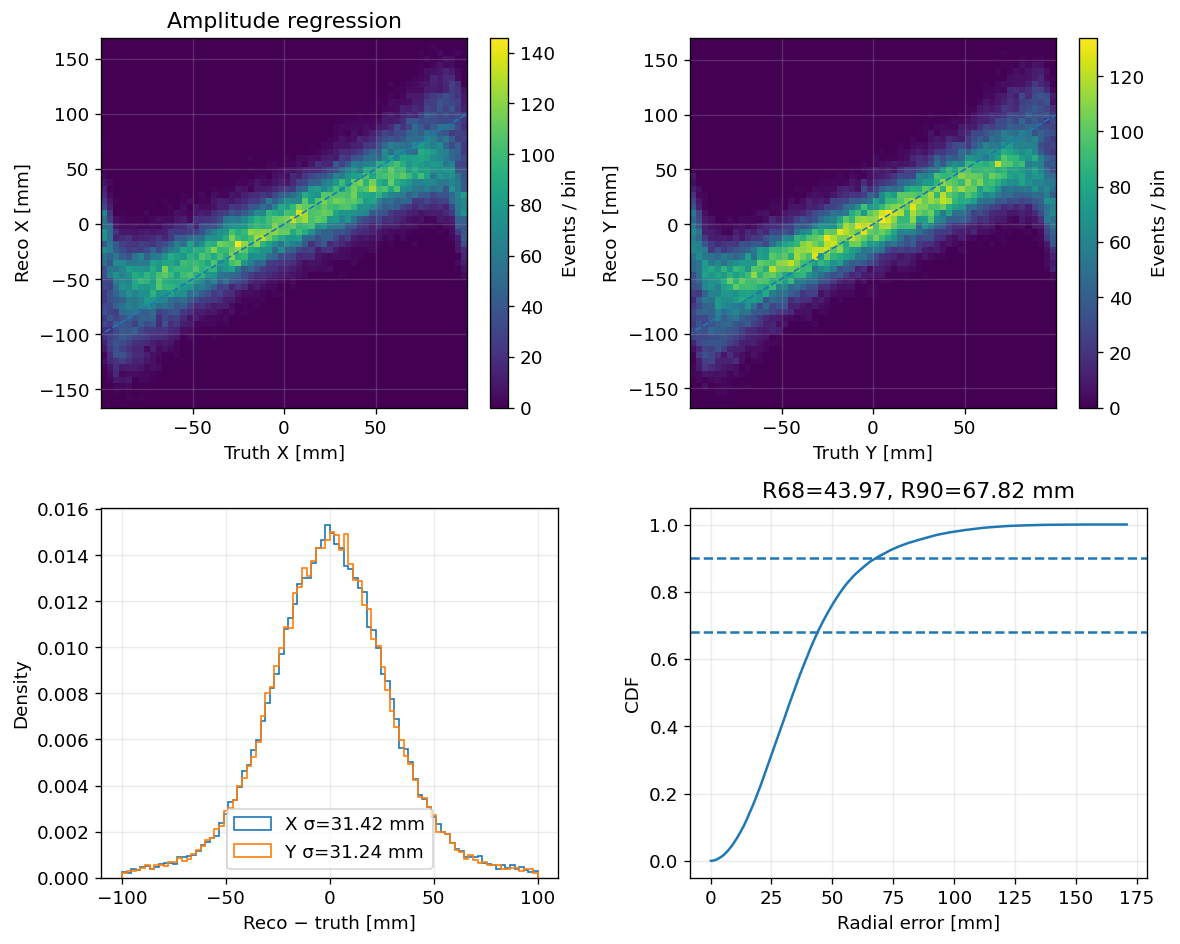

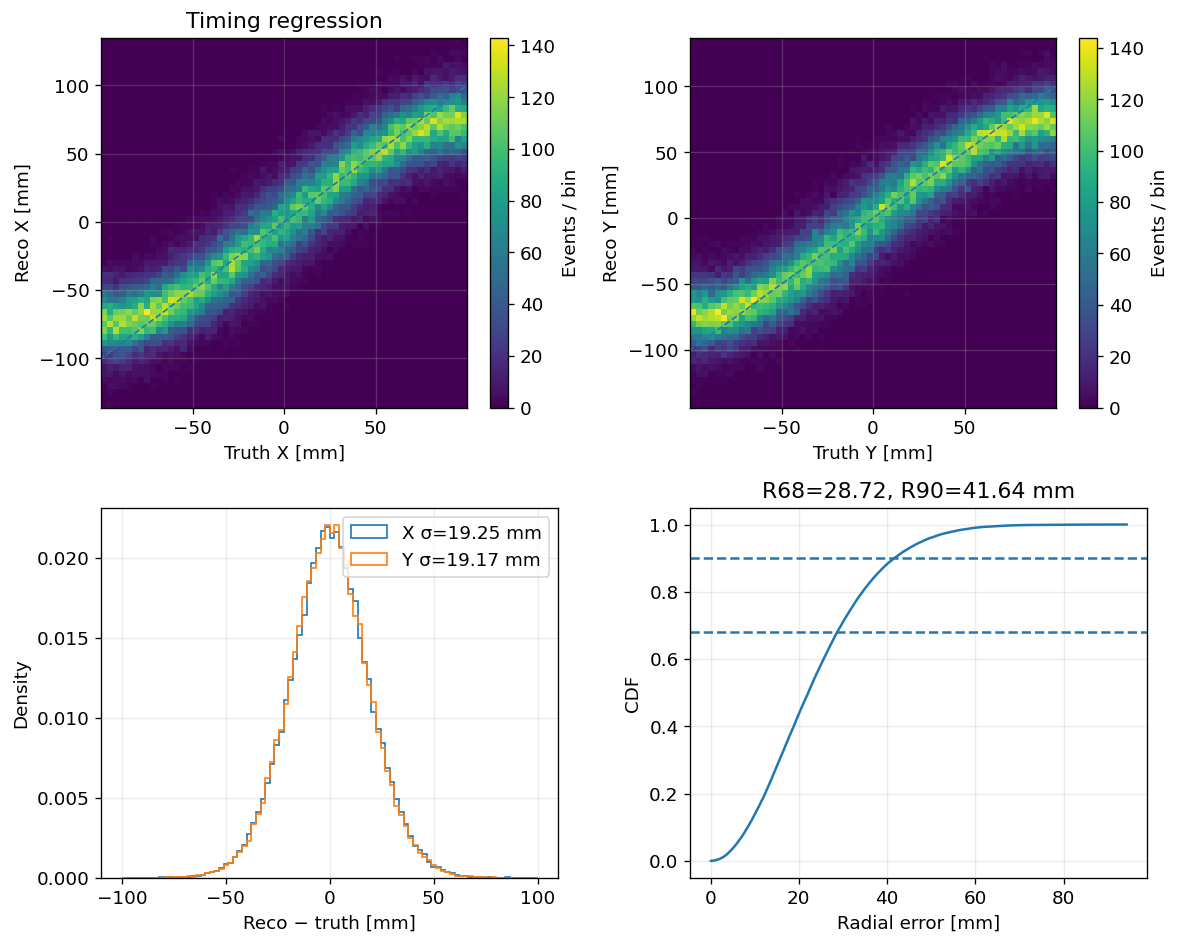

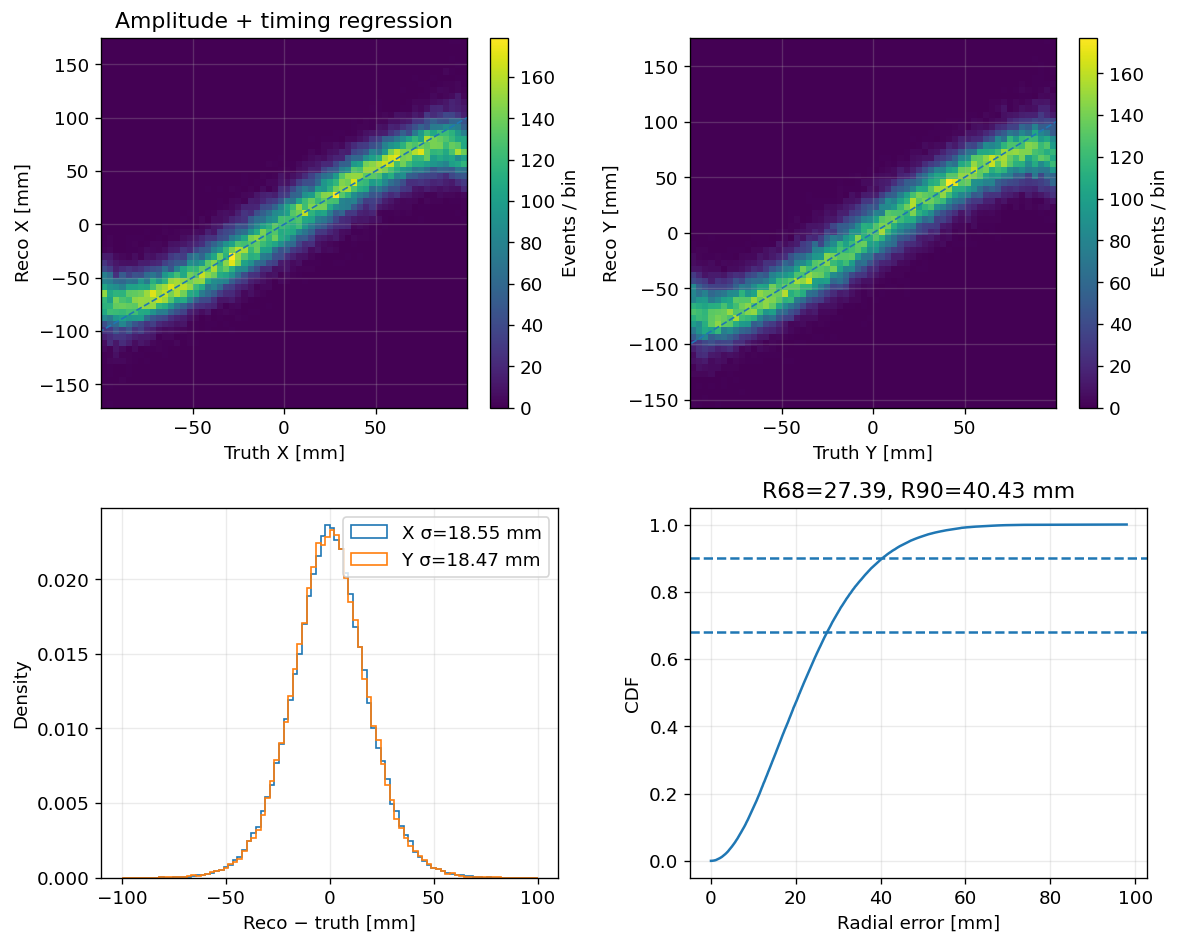

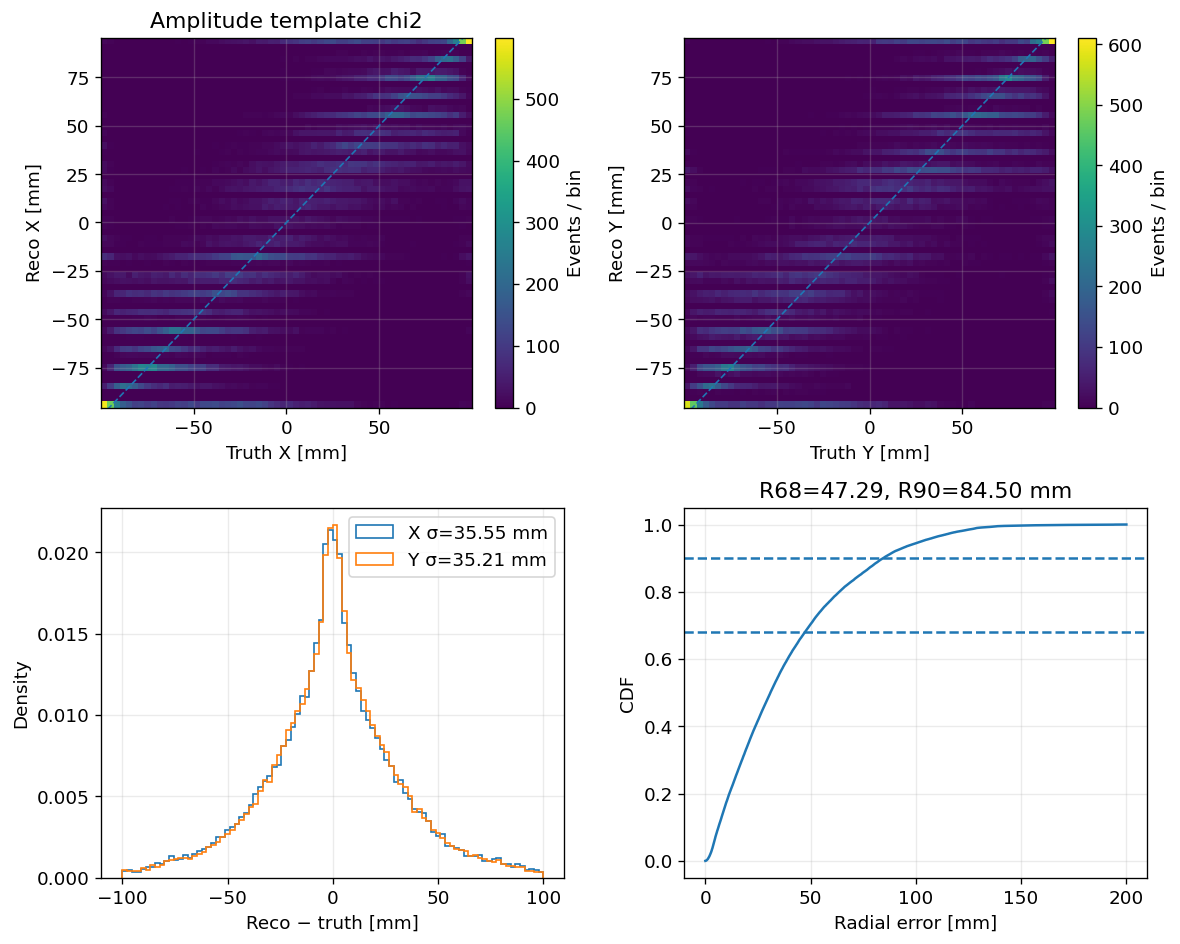

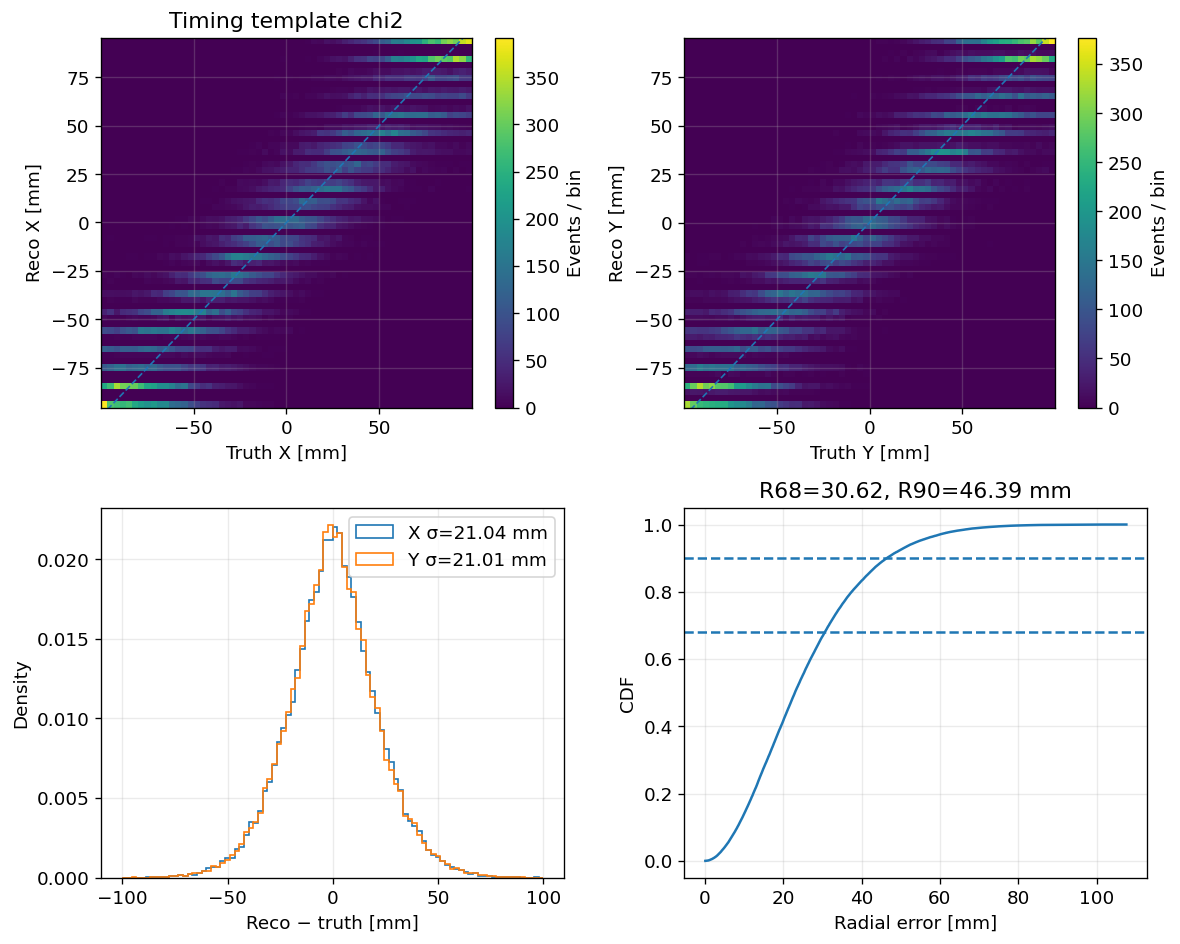

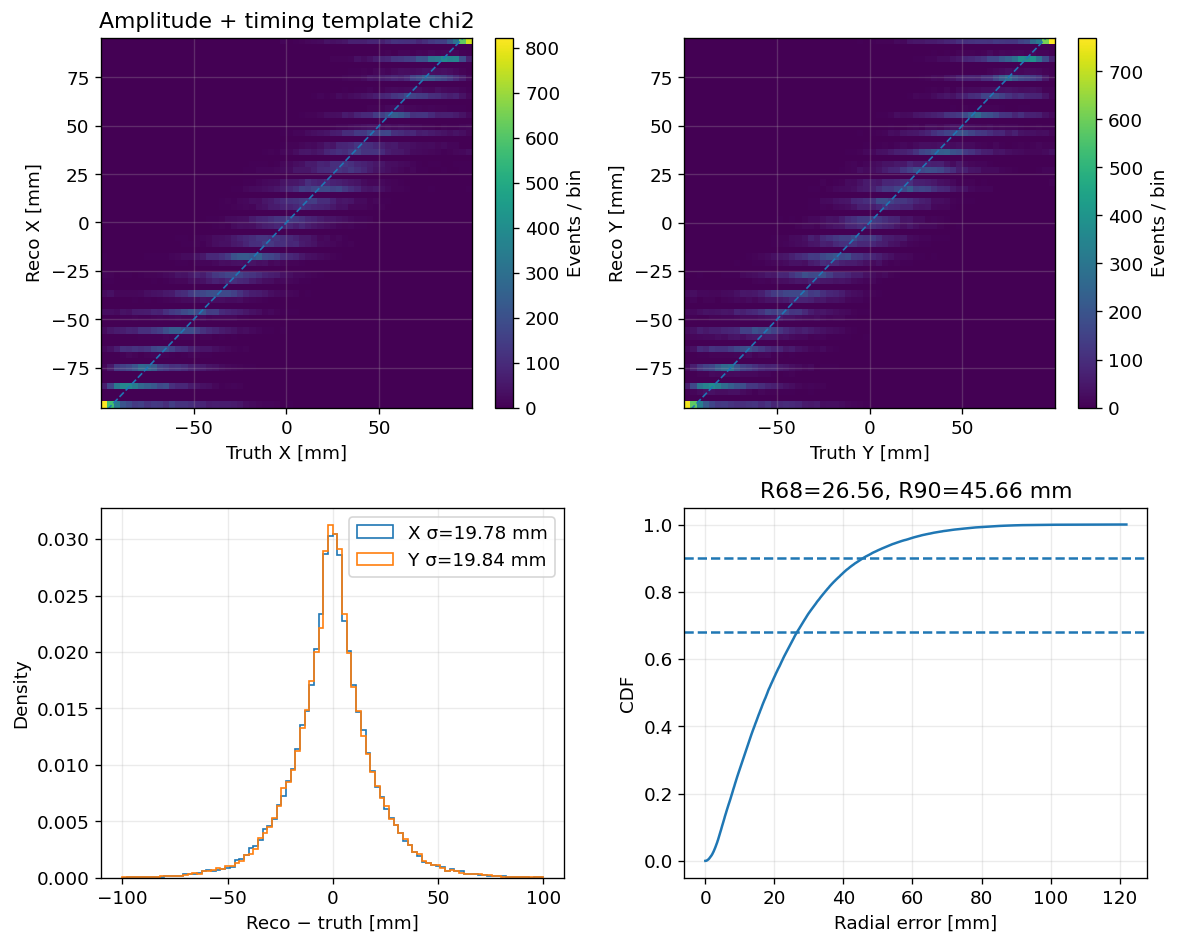

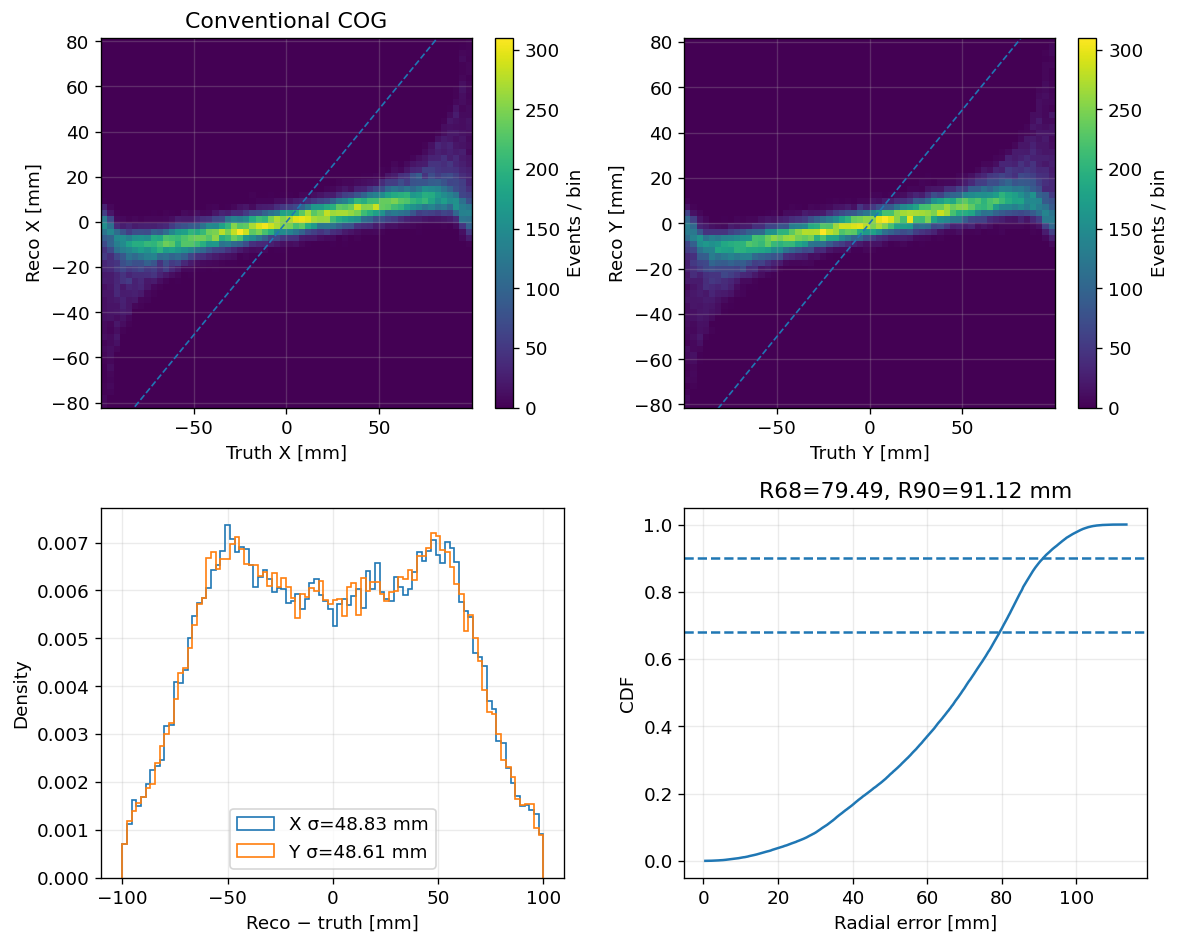

In [ ]:
# 13. Detailed residual/linearity plot for every method
def performance(name,xy):
    xt=test.source_x_mm.to_numpy(float)
    yt=test.source_y_mm.to_numpy(float)
    xr,yr=xy[:,0],xy[:,1]

    m=np.isfinite(xt)&np.isfinite(yt)&np.isfinite(xr)&np.isfinite(yr)
    xt,yt,xr,yr=xt[m],yt[m],xr[m],yr[m]

    dx=xr-xt
    dy=yr-yt
    rr=np.hypot(dx,dy)

    fig,ax=plt.subplots(2,2,figsize=(10,8))

    # regular rectangular truth-vs-reco histogram
    h=ax[0,0].hist2d(xt,xr,bins=60)
    q=[min(xt.min(),xr.min()),max(xt.max(),xr.max())]
    ax[0,0].plot(q,q,"--",lw=1)
    ax[0,0].set(
        xlabel="Truth X [mm]",
        ylabel="Reco X [mm]",
        title=name
    )
    plt.colorbar(h[3],ax=ax[0,0],label="Events / bin")

    h=ax[0,1].hist2d(yt,yr,bins=60)
    q=[min(yt.min(),yr.min()),max(yt.max(),yr.max())]
    ax[0,1].plot(q,q,"--",lw=1)
    ax[0,1].set(
        xlabel="Truth Y [mm]",
        ylabel="Reco Y [mm]"
    )
    plt.colorbar(h[3],ax=ax[0,1],label="Events / bin")

    ax[1,0].hist(
        dx,bins=90,range=(-HALF,HALF),histtype="step",density=True,
        label=f"X σ={np.std(dx):.2f} mm"
    )
    ax[1,0].hist(
        dy,bins=90,range=(-HALF,HALF),histtype="step",density=True,
        label=f"Y σ={np.std(dy):.2f} mm"
    )
    ax[1,0].set(
        xlabel="Reco − truth [mm]",
        ylabel="Density"
    )
    ax[1,0].legend()

    r=np.sort(rr)
    ax[1,1].plot(r,np.arange(1,len(r)+1)/len(r))
    ax[1,1].axhline(.68,ls="--")
    ax[1,1].axhline(.90,ls="--")
    ax[1,1].set(
        xlabel="Radial error [mm]",
        ylabel="CDF",
        title=f"R68={np.quantile(rr,.68):.2f}, R90={np.quantile(rr,.90):.2f} mm"
    )

    plt.tight_layout()
    safe=re.sub("[^A-Za-z0-9]+","_",name)
    plt.savefig(OUT/f"reco_{safe}.png",bbox_inches="tight")
    plt.show()

for name,xy in pred.items():
    performance(name,xy)

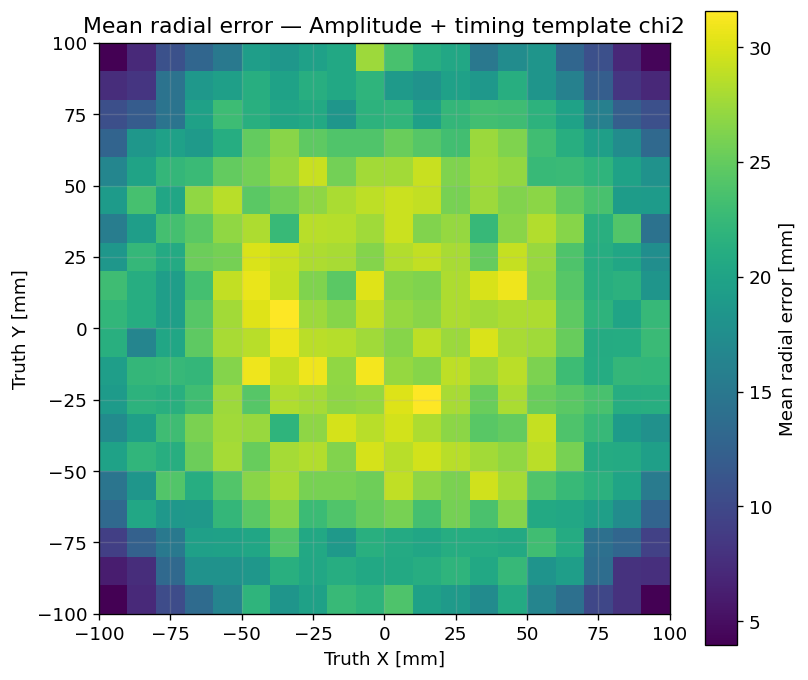

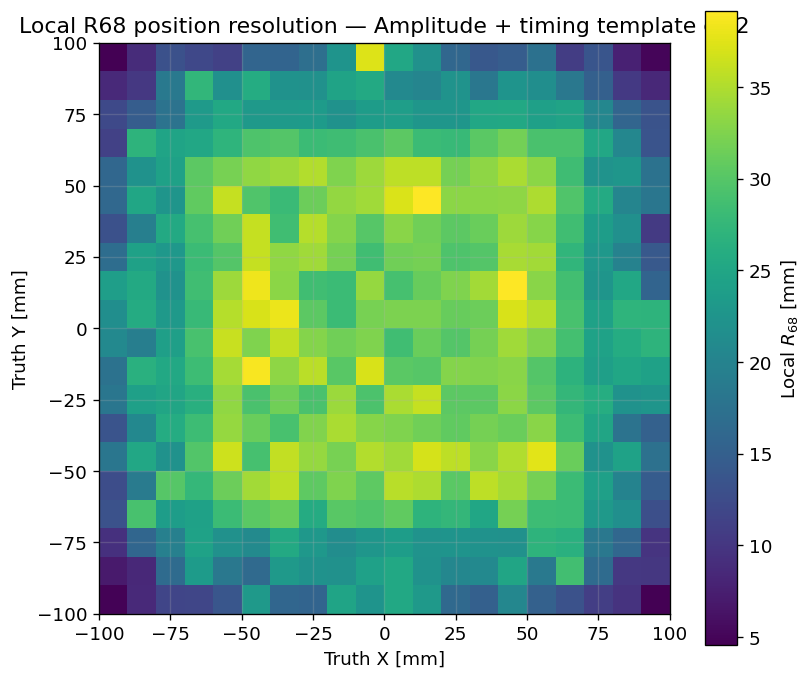

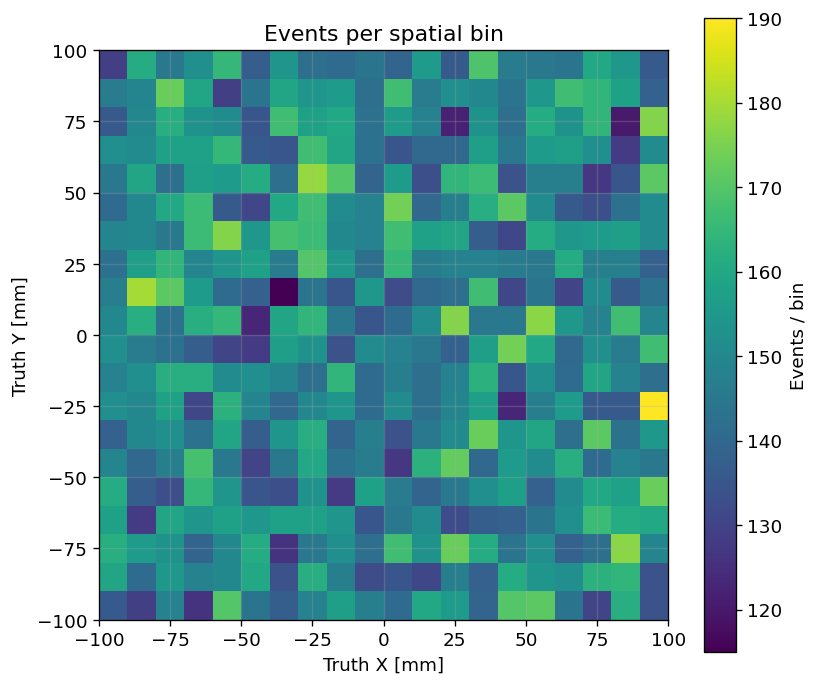

In [ ]:
# 14. Spatial resolution map for the best method
xy=pred[best]

xt=test.source_x_mm.to_numpy(float)
yt=test.source_y_mm.to_numpy(float)
dx=xy[:,0]-xt
dy=xy[:,1]-yt
r=np.hypot(dx,dy)

# ------------------------------------------------------------
# A. Mean radial error map
# ------------------------------------------------------------
fig,ax=plt.subplots(figsize=(7,6))

histmap(ax,xt,yt,z=r,statistic="mean",bins=XY_BINS,min_count=5,cbar_label="Mean radial error [mm]")
ax.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title=f"Mean radial error — {best}",xlim=(-HALF,HALF),ylim=(-HALF,HALF))

plt.tight_layout()
plt.savefig(OUT/"07_best_mean_radial_error_map.png",bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# B. R68 map -- more robust measure of local position resolution
# ------------------------------------------------------------
def q68(v):
    return np.nanquantile(v,0.68) if len(v)>=5 else np.nan

fig,ax=plt.subplots(figsize=(7,6))

histmap(ax,xt,yt,z=r,statistic=q68,bins=XY_BINS,min_count=5,cbar_label=r"Local $R_{68}$ [mm]")
ax.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title=f"Local R68 position resolution — {best}",xlim=(-HALF,HALF),ylim=(-HALF,HALF))

plt.tight_layout()
plt.savefig(OUT/"08_best_R68_map.png",bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# C. Event count map
# ------------------------------------------------------------
fig,ax=plt.subplots(figsize=(7,6))

histmap(ax,xt,yt,z=None,bins=XY_BINS,min_count=1,cbar_label="Events / bin")
ax.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title="Events per spatial bin",xlim=(-HALF,HALF),ylim=(-HALF,HALF))

plt.tight_layout()
plt.savefig(OUT/"09_spatial_event_count.png",bbox_inches="tight")
plt.show()

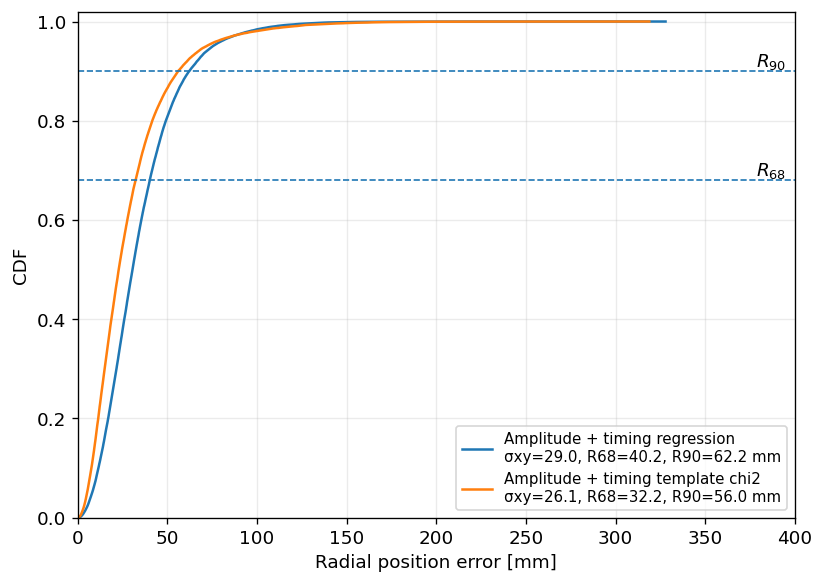

In [ ]:
# plotting the radial errr CDF for the best method
fig,ax=plt.subplots(figsize=(7,5))

for name in ["Amplitude + timing regression","Amplitude + timing template chi2"]:
    xy=pred[name]
    dx=xy[:,0]-test.source_x_mm.to_numpy()
    dy=xy[:,1]-test.source_y_mm.to_numpy()
    r=np.hypot(dx,dy); r=r[np.isfinite(r)]
    rs=np.sort(r)
    sxy=np.sqrt((np.std(dx)**2+np.std(dy)**2)/2)
    R68,R90=np.quantile(r,[.68,.90])
    ax.plot(rs,np.arange(1,len(rs)+1)/len(rs),
            label=f"{name}\nσxy={sxy:.1f}, R68={R68:.1f}, R90={R90:.1f} mm")

for y,t in [(.68,r"$R_{68}$"),(.90,r"$R_{90}$")]:
    ax.axhline(y,ls="--",lw=1); ax.text(395,y+.01,t,ha="right")

ax.set(xlabel="Radial position error [mm]",ylabel="CDF",xlim=(0,400),ylim=(0,1.02))
ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(OUT/"10_radial_error_CDF.png",bbox_inches="tight"); plt.show()

# Interpretation

For this SiPM design, the most important physics comparison is

$$
\mathrm{Amplitude\ only}
\quad\rightarrow\quad
\mathrm{Timing\ only}
\quad\rightarrow\quad
\mathrm{Amplitude+Timing}.
$$

In particular, compare:

- `Amplitude regression` with `Amplitude + timing regression`;
- `Amplitude template chi2` with `Amplitude + timing template chi2`.

A useful quantitative improvement is

$$
I_{R68}
=
\frac{R_{68}^{A}-R_{68}^{A+T}}{R_{68}^{A}}\times100\%.
$$

If the combined estimator improves $R_{68}$, $\sigma_x$, and $\sigma_y$ consistently across the detector surface, that is direct evidence that timing adds independent spatial information.

The template method is especially relevant for a real prototype because the response maps can eventually be obtained using a scanned source or an external tracking telescope.

### Experimental realism

The present timing resolution is an optical-limit result unless the simulation also includes SiPM/electronics effects such as SPTR/TTS, PDE fluctuations, dark counts, crosstalk, afterpulsing, electronics noise/bandwidth and the actual timing-pickoff method.